# HDB Rentals: EDA of `data/auxiliary/sg-schools.csv`

School inventory for area-level density. This notebook cleans names, aligns planning-area spelling
with the HDB crosswalk, parses the two free-text transport columns (`MRT_STATIONS`, `BUS_LINES`)
into clean lists, and counts schools per area.

The 1 km primary-school count lives in `03_feature_rmse.ipynb`, not here.

**Free-text columns:** `MRT_STATIONS` and `BUS_LINES` are typed by hand at MOE and are messy. Sections
4(d) and 4(e) show what they actually look like, section 5b parses them, and section 5c checks the
parse against the MRT reference table and the school coordinates. The raw (lowercased) columns are
kept; the parsed ones are added next to them.

1. Why this table exists
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()`
4. Data-quality issues
5. A cleaned analysis frame (5b parse MRT / bus text, 5c validate the parse)
6. School mix and geography
7. Area-level school features
8. Summary


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA = ROOT / "data"
AUX = DATA / "auxiliary"
CLEANED = ROOT / "cleaned"
OUT = ROOT / "outputs"
OUT_DIR = OUT
CLEANED.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

SG_LAT = (1.13, 1.47)
SG_LON = (103.6, 104.1)


def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append(
            {
                "dtype": str(s.dtype),
                "n_unique": s.nunique(dropna=True),
                "unique_pct": 100 * s.nunique(dropna=True) / len(s),
                "n_missing": s.isna().sum(),
                "missing_pct": 100 * s.isna().mean(),
                "examples": ", ".join(map(str, s.dropna().unique()[:4])),
            }
        )
    return pd.DataFrame(rows, index=df.columns)


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out

schools_raw = pd.read_csv(AUX / "sg-schools.csv")
hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv")
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
print(f"schools: {schools_raw.shape}   hdb cleaned: {hdb.shape}   mrt cleaned: {mrt.shape}")
schools_raw.head()


schools: (337, 14)   hdb cleaned: (9464, 12)   mrt cleaned: (243, 10)


,NAME,URL,STREET,POSTAL_CODE,MRT_STATIONS,BUS_LINES,PLANNING_AREA,REGION,TYPE_CODE,NATRUE_CODE,SESSION_CODE,MAINLEVEL_CODE,LATITUDE,LONGITUDE
0,admiralty primary school,https://admiraltypri.moe.edu.sg/,11 woodlands circle,738907,admiralty station,"965, 964, 913",woodlands,north,government school,co-ed school,full day,primary,1.443,103.800
1,admiralty secondary school,http://www.admiraltysec.moe.edu.sg,31 woodlands crescent,737916,admiralty mrt,904,woodlands,north,government school,co-ed school,single session,secondary (s1-s5),1.446,103.802
2,ahmad ibrahim primary school,http://www.ahmadibrahimpri.moe.edu.sg,10 yishun street 11,768643,yishun,yishun ring road - 812 (white plate); yishun a...,yishun,north,government school,co-ed school,single session,primary,1.433,103.833
3,ahmad ibrahim secondary school,http://www.ahmadibrahimsec.moe.edu.sg,751 yishun avenue 7,768928,"canberra mrt, yishun mrt","117, 167, 169, 800, 811, 812, 883, 856, 858, 8...",yishun,north,government school,co-ed school,single session,secondary (s1-s5),1.436,103.830
4,ai tong school,http://www.aitong.moe.edu.sg,100 bright hill drive,579646,bishan mrt,"410, 162, 52",bishan,south,government-aided sch,co-ed school,single session,primary,1.361,103.833


## 1. Why this table exists

`BUS_LINES` contains quoted commas (`"965, 964, 913"`), so the file must be read with a real CSV
parser. Schools join to rentals through `PLANNING_AREA` from the HDB crosswalk. A spelling mismatch
here zeroes out school counts for a whole town. Area-level totals are tested in
`03_feature_rmse.ipynb` and do not beat `TOWN`.


## 2. Structure, dtypes and missingness


In [2]:
schools_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337 entries, 0 to 336
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   NAME            337 non-null    object 
 1   URL             337 non-null    object 
 2   STREET          337 non-null    object 
 3   POSTAL_CODE     337 non-null    int64  
 4   MRT_STATIONS    337 non-null    object 
 5   BUS_LINES       337 non-null    object 
 6   PLANNING_AREA   337 non-null    object 
 7   REGION          337 non-null    object 
 8   TYPE_CODE       337 non-null    object 
 9   NATRUE_CODE     337 non-null    object 
 10  SESSION_CODE    337 non-null    object 
 11  MAINLEVEL_CODE  337 non-null    object 
 12  LATITUDE        337 non-null    float64
 13  LONGITUDE       337 non-null    float64
dtypes: float64(2), int64(1), object(11)
memory usage: 37.0+ KB


In [3]:
column_profile(schools_raw)


,dtype,n_unique,unique_pct,n_missing,missing_pct,examples
NAME,object,337,100.000,0,0.000,"admiralty primary school, admiralty secondary ..."
URL,object,337,100.000,0,0.000,"https://admiraltypri.moe.edu.sg/, http://www.a..."
STREET,object,335,99.407,0,0.000,"11 woodlands circle, 31 woodlands crescent, 10..."
POSTAL_CODE,int64,335,99.407,0,0.000,"738907, 737916, 768643, 768928"
MRT_STATIONS,object,251,74.481,0,0.000,"admiralty station, admiralty mrt, yishun, canb..."
BUS_LINES,object,326,96.736,0,0.000,"965, 964, 913, 904, yishun ring road - 812 (wh..."
PLANNING_AREA,object,28,8.309,0,0.000,"woodlands, yishun, bishan, bukit merah"
REGION,object,4,1.187,0,0.000,"north, south, east, west"
TYPE_CODE,object,5,1.484,0,0.000,"government school, government-aided sch, indep..."
NATRUE_CODE,object,3,0.890,0,0.000,"co-ed school, boys' school, girls' school"


In [4]:
print("fully duplicated rows:", schools_raw.duplicated().sum())
print("duplicated NAME:", schools_raw.duplicated("NAME").sum())


fully duplicated rows: 0
duplicated NAME: 0


## 3. `.describe()`


In [5]:
num_cols = schools_raw.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in schools_raw.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

schools_raw[num_cols].describe().T


numeric    : ['POSTAL_CODE', 'LATITUDE', 'LONGITUDE']
categorical: ['NAME', 'URL', 'STREET', 'MRT_STATIONS', 'BUS_LINES', 'PLANNING_AREA', 'REGION', 'TYPE_CODE', 'NATRUE_CODE', 'SESSION_CODE', 'MAINLEVEL_CODE']


,count,mean,std,min,25%,50%,75%,max
POSTAL_CODE,337.000,"540,886.950","188,388.150","88,256.000","449,150.000","549,936.000","679,944.000","828,870.000"
LATITUDE,337.000,1.361,0.042,1.275,1.331,1.354,1.388,1.457
LONGITUDE,337.000,103.841,0.070,103.687,103.785,103.843,103.897,103.963


In [6]:
schools_raw[cat_cols].describe().T


,count,unique,top,freq
NAME,337,337,admiralty primary school,1
URL,337,337,https://admiraltypri.moe.edu.sg/,1
STREET,337,335,190 dunearn road,2
MRT_STATIONS,337,251,pasir ris mrt,6
BUS_LINES,337,326,na,3
PLANNING_AREA,337,28,woodlands,22
REGION,337,4,east,85
TYPE_CODE,337,5,government school,243
NATRUE_CODE,337,3,co-ed school,293
SESSION_CODE,337,2,single session,319


## 4. Data-quality issues

These are join bugs or source quirks, not NaNs.


In [7]:
# (a) Spelling: schools use "seng kang"; HDB blocks use "sengkang". Lowercase/strip does not catch this.
print("planning-area values that look like sengkang:")
print(sorted(a for a in schools_raw["PLANNING_AREA"].unique() if "kang" in a))
print("rows with PLANNING_AREA == 'seng kang':",
      (schools_raw["PLANNING_AREA"] == "seng kang").sum())


planning-area values that look like sengkang:
['choa chu kang', 'seng kang']
rows with PLANNING_AREA == 'seng kang': 19


In [8]:
# (b) REGION is MOE's 4-zone system, and it is not even consistent inside a planning area.
print("school REGION (MOE zone):")
print(schools_raw["REGION"].value_counts(), "\n")
inconsistent = (
    schools_raw.groupby("PLANNING_AREA")["REGION"].nunique().loc[lambda s: s > 1]
)
print("planning areas with more than one MOE REGION:")
print(inconsistent.to_string())
print("\ncolumn name NATRUE_CODE is a source typo for NATURE.")
print(schools_raw["NATRUE_CODE"].value_counts())


school REGION (MOE zone):
REGION
east     85
north    84
south    84
west     84
Name: count, dtype: int64 

planning areas with more than one MOE REGION:
PLANNING_AREA
ang mo kio     2
bishan         2
bukit timah    2
hougang        3
kallang        2
punggol        2
queenstown     2
serangoon      2
toa payoh      2

column name NATRUE_CODE is a source typo for NATURE.
NATRUE_CODE
co-ed school     293
girls' school     29
boys' school      15
Name: count, dtype: int64


In [9]:
# (c) Four schools are labelled PLANNING_AREA == 'central', which is a town, not a URA area.
central = schools_raw[schools_raw["PLANNING_AREA"].str.lower() == "central"]
print(f"{len(central)} schools labelled 'central':")
central[["NAME", "STREET", "PLANNING_AREA", "REGION", "MRT_STATIONS"]]


4 schools labelled 'central':


,NAME,STREET,PLANNING_AREA,REGION,MRT_STATIONS
16,anglo-chinese school (junior),16 winstedt road,central,south,newton mrt station
235,river valley primary school,2 river valley green,central,south,somerset mrt
242,"school of the arts, singapore",1 zubir said drive 05 01,central,south,dhoby ghaut
271,st. margaret's school (primary),136 sophia road,central,south,"little india mrt station (ne7/dt12), dhoby gha..."


### 4(d) `MRT_STATIONS` — what it really looks like

The column is one free-text field per school. Before writing a parser, count what kinds of text are
in it. The flags below are not exclusive: one cell can be bare-name *and* multi-station *and* carry a code.

In [10]:
import re

m = schools_raw["MRT_STATIONS"].str.strip().str.lower()
checks = {
    "bare name, no 'mrt'/'station'/'lrt' word":  ~m.str.contains(r"\b(?:mrt|lrt|station|stations)\b"),
    "several stations (, & and / ; or)":           m.str.contains(r",|&|;|/|\band\b|\bor\b"),
    "station code in text (ne16, ew28 ...)":        m.str.contains(r"\b(?:ns|ew|ne|cc|dt|te|se|sw|pe|pw)\s?\d{1,2}\b"),
    "mentions an LRT station":                      m.str.contains(r"\blrt\b"),
    "line name (circle line, tel, nel ...)":        m.str.contains(r"\bline\b|\btel\b|\bnel\b"),
    "walking time / distance note":                 m.str.contains(r"\bwalk\b|\bmin|\bkm\b"),
    "bus numbers inside the MRT column":            m.str.contains(r"\bbus\b"),
    "directions / instructions":                    m.str.contains(r"\balight\b|\bexit\b|\bpending\b"),
    "placeholder (na / nil)":                       m.isin(["na", "nil"]),
}
tax = pd.DataFrame(
    {"n_rows": {k: int(v.sum()) for k, v in checks.items()},
     "example": {k: m[v].iloc[0] if v.any() else "" for k, v in checks.items()}}
)
print("distinct raw strings:", m.nunique(), "of", len(m), "rows")
tax

distinct raw strings: 251 of 337 rows


,n_rows,example
"bare name, no 'mrt'/'station'/'lrt' word",61,yishun
"several stations (, & and / ; or)",134,"canberra mrt, yishun mrt"
"station code in text (ne16, ew28 ...)",15,"mrt : ne16-sengkang, lrt : sw7-tongkang"
mentions an LRT station,35,"mrt : ne16-sengkang, lrt : sw7-tongkang"
"line name (circle line, tel, nel ...)",9,"downtown line 2, cashew mrt"
walking time / distance note,5,nearest mrt station: mattar station (about 3-m...
bus numbers inside the MRT column,2,"eunos station (transfer bus no.63, 63m), ubi s..."
directions / instructions,2,from pending lrt station to choa chu kang mrt ...
placeholder (na / nil),4,nil


In [11]:
# The same station is spelled several ways, so an exact string join to the MRT table finds almost nothing.
print("raw strings that mention 'yishun':")
print(m[m.str.contains("yishun")].value_counts().to_string())

mrt["BASE"] = mrt["NAME"].str.replace(r"\s+mrt(?:/lrt)?\s+station$", "", regex=True)
exact = m.isin(set(mrt["NAME"]))
print(f"\nrows whose whole text equals an MRT-table NAME exactly: {exact.sum()} / {len(m)}")
print("LRT stations (kadaloor, jelapang, fajar ...) are not in the MRT table at all:",
      not mrt["NAME"].str.contains("kadaloor|jelapang|fajar").any())

raw strings that mention 'yishun':
MRT_STATIONS
yishun mrt station                                                                      5
yishun                                                                                  2
yishun, khatib                                                                          2
yishun mrt, khatib mrt                                                                  2
yishun mrt                                                                              2
canberra mrt, yishun mrt                                                                1
o   alight at yishun mrt station, o   take exit c, o   walk towards yishun street 21    1

rows whose whole text equals an MRT-table NAME exactly: 43 / 337
LRT stations (kadaloor, jelapang, fajar ...) are not in the MRT table at all: True


Findings for `MRT_STATIONS`:

- **Spelling:** `admiralty`, `admiralty mrt`, `admiralty station`, `admiralty mrt station` all occur, so
  the station name has to be pulled out of the text; an exact join to the MRT table matches only a
  small minority.
- **Several stations per cell** with five different separators (`,` `&` `and` `/` `;`), sometimes with a
  dangling comma or `or ,`.
- **LRT stations** (Sengkang, Punggol, Bukit Panjang loops) are mixed in. The MRT reference table has no
  LRT stations except the hub rows (`punggol mrt/lrt station` ...), so LRT names need their own list.
- **Not stations at all:** `na` / `nil`, walking times, `alight at ... take exit c`, campus names, bus numbers
  (`transfer bus no.63`), and street names that contain a station name (`yishun street 21`).
- **Line names that look like stations:** `downtown line 2` would match the *Downtown* station.
- **Codes** (`ne16`, `ew28`) are given for some stations. They are ignored for matching but used in 5c to
  cross-check the names.

### 4(e) `BUS_LINES` — what it really looks like

Same approach: classify the text first. Most cells are a comma-separated list of service numbers, but a
sizeable minority carry extra words and *extra numbers that are not bus services*.

In [12]:
b = schools_raw["BUS_LINES"].str.strip().str.lower()
plain = b.str.fullmatch(r"\d{1,3}[a-z]?(?:, \d{1,3}[a-z]?)*")
checks = {
    "plain 'n, n, n' list":                          plain,
    "operator / label words (sbs, tibs, smrt, feeder, bus ...)": b.str.contains(r"[a-z]{3,}") & ~b.str.contains(r"^na$"),
    "separator is not a comma (space, ; , & , and)":  b.str.contains(r";|&|\band\b") | b.str.contains(r"\d[a-z]? \d"),
    "grouped by road / stop (colon or ' - ')":         b.str.contains(r":| - "),
    "5-digit bus-stop ids mixed in":                   b.str.contains(r"\b\d{5}\b"),
    "placeholder '000' padding":                       b.str.contains(r"\b000\b"),
    "letter suffix (16m, 196e, 243g/w)":               b.str.contains(r"\b\d{1,3}[a-z]\b"),
    "prefixed services (nr3, ct18, fs238, 1n)":         b.str.contains(r"\b(?:nr|ct|fs)\d+\b|\b\d+n\b"),
    "address numbers (ave 2, blk 220, at 3 york hill)": b.str.contains(r"\b(?:ave|street|road|blk|st)\s*\d+|\bat \d+ [a-z]"),
    "times / durations (7.00 am, 1-2 min walk)":        b.str.contains(r"\d[.:]\d{2}\s*[ap]m|\bmin\b"),
    "no bus information (na / sentence)":               b.eq("na") | ~b.str.contains(r"\d"),
}
tax = pd.DataFrame(
    {"n_rows": {k: int(v.sum()) for k, v in checks.items()},
     "example": {k: b[v].iloc[0][:90] if v.any() else "" for k, v in checks.items()}}
)
print("distinct raw strings:", b.nunique(), "of", len(b), "rows")
tax

distinct raw strings: 326 of 337 rows


,n_rows,example
"plain 'n, n, n' list",248,"965, 964, 913"
"operator / label words (sbs, tibs, smrt, feeder, bus ...)",69,yishun ring road - 812 (white plate); yishun a...
"separator is not a comma (space, ; , & , and)",31,yishun ring road - 812 (white plate); yishun a...
grouped by road / stop (colon or ' - '),17,yishun ring road - 812 (white plate); yishun a...
5-digit bus-stop ids mixed in,3,"76281: 46, 65, 129, 76061: 10, 15, 20, 21, 23,..."
placeholder '000' padding,3,"76, 132, 165, 166, 169, 200, 000, 000"
"letter suffix (16m, 196e, 243g/w)",77,"25, 55, 62, 80, 81, 82, 101, 107, 107m, 112, 1..."
"prefixed services (nr3, ct18, fs238, 1n)",7,"4n, 13, 16, 31, 36, 36a, 36b, 43, 47, 48, 55, ..."
"address numbers (ave 2, blk 220, at 3 york hill)",10,yishun ring road - 812 (white plate); yishun a...
"times / durations (7.00 am, 1-2 min walk)",2,900a (weekdays only - 7.00 am to 8.30 am & 4.3...


Findings for `BUS_LINES`:

- **The trap:** pulling every number out of the text is wrong. `yishun ave 2 - 169, 804` has an avenue
  number, `alight at blk 220 ... blk 227 or 236` has block numbers, `at 3 york hill` a street number,
  `7.00 am to 8.30 am` clock times, and `(bus stop ids: 47549 ...)` five-digit stop ids. None are services.
  The parser strips these patterns first (5b) and 5c lists exactly what was dropped.
- **Padding:** `000, 000, ...` is a placeholder, not service 0.
- **Suffixes are part of the service:** `196e`, `243g/w` (two services, `243g` and `243w`), `901m`. Night / express
  labels (`nr3`, `1n`, `ct18`, `fs238`) are kept as they are.
- **Repeats:** the same service is often listed twice (`972, 972a, 972, 972a`, two campuses, two stops) so lists are de-duplicated.
- **Grouping by road or stop is lost** on purpose: the result is the *set* of distinct services near the school.
- **No information:** `na`, or a sentence such as `we are just beside clementi bus interchange.`; these give an empty list, not a fabricated one.

In [13]:
# (f) Coordinates.
bad_coords = schools_raw[
    ~schools_raw["LATITUDE"].between(*SG_LAT) | ~schools_raw["LONGITUDE"].between(*SG_LON)
]
print(f"out-of-bounds coordinates: {len(bad_coords)}")

print("bounding box only catches gross errors; section 5c checks coordinates against addresses and named stations.")

out-of-bounds coordinates: 0
bounding box only catches gross errors; section 5c checks coordinates against addresses and named stations.


`seng kang` is a spelling variant of `sengkang`. `central` is not a URA planning area at all
— those four schools are assigned the `PLANNING_AREA` of the nearest MRT station. `REGION` is
then taken from the HDB/MRT URA map so all three auxiliary tables share the same five regions.

`MRT_STATIONS` and `BUS_LINES` are free text with the problems in 4(d) and 4(e). They are parsed in
5b and the parse is checked in 5c.

## 5. A cleaned analysis frame

Alias `seng kang`, resolve `central` via nearest MRT, add `STREET_NAME`, replace MOE `REGION`
with the URA region of the (cleaned) planning area. Keep `NATRUE_CODE` as in the source.

Section 5b then parses `MRT_STATIONS` and `BUS_LINES` into clean lists and 5c validates them.

In [14]:
PLANNING_AREA_ALIASES = {"seng kang": "sengkang"}


def haversine_m(lat1, lon1, lat2, lon2):
    r = 6_371_000.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def clean_schools(df: pd.DataFrame, hdb: pd.DataFrame, mrt: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df)
    out["PLANNING_AREA_MOE"] = out["PLANNING_AREA"]  # raw MOE value, before the sengkang alias and the central-MRT remap
    out["PLANNING_AREA"] = out["PLANNING_AREA"].replace(PLANNING_AREA_ALIASES)
    out["LATITUDE"] = pd.to_numeric(out["LATITUDE"], errors="coerce")
    out["LONGITUDE"] = pd.to_numeric(out["LONGITUDE"], errors="coerce")
    out["REGION_MOE"] = out["REGION"]
    parsed = out["STREET"].str.extract(r"^(?P<HOUSE_NO>\S+)\s+(?P<STREET_NAME>.+)$")
    out["STREET_NAME"] = parsed["STREET_NAME"].fillna(out["STREET"])

    central = out["PLANNING_AREA"].eq("central")
    mrt_lat, mrt_lon = mrt["LATITUDE"].to_numpy(), mrt["LONGITUDE"].to_numpy()
    for idx in out.index[central]:
        d = haversine_m(out.at[idx, "LATITUDE"], out.at[idx, "LONGITUDE"], mrt_lat, mrt_lon)
        nearest = mrt.iloc[int(np.argmin(d))]
        print(f"  {out.at[idx, 'NAME']}: central -> {nearest['PLANNING_AREA']} "
              f"(nearest {nearest['NAME']}, {d.min():.0f} m)")
        out.at[idx, "PLANNING_AREA"] = nearest["PLANNING_AREA"]

    area_region = (
        pd.concat([hdb[["PLANNING_AREA", "REGION"]], mrt[["PLANNING_AREA", "REGION"]]], ignore_index=True)
        .drop_duplicates("PLANNING_AREA")
        .set_index("PLANNING_AREA")["REGION"]
    )
    out["REGION"] = out["PLANNING_AREA"].map(area_region)
    return out.reset_index(drop=True)


print("resolving PLANNING_AREA == 'central' via nearest MRT:")
schools = clean_schools(schools_raw, hdb, mrt)
print("\nURA REGION after alignment:")
print(schools["REGION"].value_counts())
print("REGION still missing:", schools["REGION"].isna().sum())
schools.head(3)


resolving PLANNING_AREA == 'central' via nearest MRT:
  anglo-chinese school (junior): central -> newton (nearest newton mrt station, 504 m)
  river valley primary school: central -> river valley (nearest great world mrt station, 312 m)
  school of the arts, singapore: central -> rochor (nearest bencoolen mrt station, 185 m)
  st. margaret's school (primary): central -> museum (nearest dhoby ghaut mrt station, 507 m)

URA REGION after alignment:
REGION
central region       87
north-east region    75
west region          74
east region          53
north region         48
Name: count, dtype: int64
REGION still missing: 0


,NAME,URL,STREET,POSTAL_CODE,MRT_STATIONS,BUS_LINES,PLANNING_AREA,REGION,TYPE_CODE,NATRUE_CODE,SESSION_CODE,MAINLEVEL_CODE,LATITUDE,LONGITUDE,PLANNING_AREA_MOE,REGION_MOE,STREET_NAME
0,admiralty primary school,https://admiraltypri.moe.edu.sg/,11 woodlands circle,738907,admiralty station,"965, 964, 913",woodlands,north region,government school,co-ed school,full day,primary,1.443,103.800,woodlands,north,woodlands circle
1,admiralty secondary school,http://www.admiraltysec.moe.edu.sg,31 woodlands crescent,737916,admiralty mrt,904,woodlands,north region,government school,co-ed school,single session,secondary (s1-s5),1.446,103.802,woodlands,north,woodlands crescent
2,ahmad ibrahim primary school,http://www.ahmadibrahimpri.moe.edu.sg,10 yishun street 11,768643,yishun,yishun ring road - 812 (white plate); yishun a...,yishun,north region,government school,co-ed school,single session,primary,1.433,103.833,yishun,north,yishun street 11


In [15]:
hdb_areas = set(hdb["PLANNING_AREA"].dropna().unique())
school_areas = set(schools["PLANNING_AREA"].unique())
print("HDB planning areas with no school row:", sorted(hdb_areas - school_areas))
print("school planning areas with no HDB block:", sorted(school_areas - hdb_areas))
print("REGION mismatches vs HDB on shared areas:",
      (schools.merge(hdb.drop_duplicates("PLANNING_AREA")[["PLANNING_AREA", "REGION"]],
                     on="PLANNING_AREA", how="inner", suffixes=("_sch", "_hdb"))
       .assign(bad=lambda d: d["REGION_sch"] != d["REGION_hdb"])["bad"].sum()))


HDB planning areas with no school row: ['changi', 'downtown core', 'outram', 'tanglin']
school planning areas with no HDB block: ['museum', 'newton', 'river valley', 'tengah']
REGION mismatches vs HDB on shared areas: 0


### 5b. Parsing `MRT_STATIONS` and `BUS_LINES`

**MRT.** Station names come from the cleaned MRT table (`BASE` = name without `mrt station`), matched as whole
words, longest name first so `tampines east` wins over `tampines` and `woodlands south` over `woodlands`.
Before matching, three kinds of text that contain station-looking words are removed: line names
(`downtown line`), bus references (`bus no.63`) and street names (`yishun street 21`). LRT stations are matched
against a small hand-written list, because the MRT table has none. Three abbreviations are aliased
(`lor chuan`, `farrer rd`, `bt panjang`).

**Bus.** Strip address numbers, clock times, durations, stop ids and `000` padding, then keep tokens that look
like a service (`123`, `123a`, `nr3`, `ct18`, `fs238`, `1n`), expand `243g/w`, and de-duplicate in order.

In [16]:
# ---- MRT ----
# Hand-written: the MRT reference table has no LRT stations (only the hub rows such as "punggol mrt/lrt station").
LRT_STATIONS = [
    # Bukit Panjang loop
    "south view", "keat hong", "teck whye", "phoenix", "petir", "pending", "bangkit", "fajar", "segar",
    "jelapang", "senja",
    # Sengkang loop
    "compassvale", "rumbia", "bakau", "kangkar", "ranggung", "cheng lim", "farmway", "kupang", "thanggam",
    "fernvale", "layar", "tongkang", "renjong",
    # Punggol loop
    "cove", "meridian", "coral edge", "kadaloor", "oasis", "damai", "sam kee", "teck lee", "punggol point",
    "samudera", "nibong", "sumang", "soo teck",
]
LRT_ALIASES = {"southview": "south view", "puggol point": "punggol point"}   # "puggol" is a typo in the source
MRT_ALIASES = {"lor chuan": "lorong chuan", "farrer rd": "farrer road", "bt panjang": "bukit panjang"}

mrt_ref = (
    mrt.assign(BASE=mrt["NAME"].str.replace(r"\s+mrt(?:/lrt)?\s+station$", "", regex=True))
    .groupby("BASE")
    .agg(LATITUDE=("LATITUDE", "mean"), LONGITUDE=("LONGITUDE", "mean"),
         IS_OPEN=("STATUS", lambda s: (s == "open").any()), CODES=("CODE", lambda s: sorted(set(s))))
)


def _alternation(names):
    # longest first: regex alternation takes the first branch that matches at a position
    ordered = sorted(set(names), key=len, reverse=True)
    return re.compile(r"(?<![a-z])(" + "|".join(re.escape(n) for n in ordered) + r")(?![a-z])")


_MRT_RE = _alternation(list(mrt_ref.index) + list(MRT_ALIASES))
_LRT_RE = _alternation(LRT_STATIONS + list(LRT_ALIASES))
_MRT_NOISE = [
    r"\b(?:downtown|east[- ]?west|north[- ]?south|north[- ]?east|circle|thomson[- ]east coast|cross island)\s+line\b",
    r"\bbus\s+no\.?\s*\d+[a-z]?(?:\s*,\s*\d+[a-z]?)*",
    r"\b[a-z]+\s+(?:street|avenue|ave|road|rd)\s+\d+\b",
    r"\([^)]*\bloop\b[^)]*\)",   # "(sengkang west loop)" names an LRT branch, not a nearby Sengkang MRT station
]
_CODE_RE = re.compile(r"\b(ns|ew|ne|cc|dt|te|cg|ce)\s?(\d{1,2})\b")


def _unique(seq):
    return list(dict.fromkeys(seq))


def parse_mrt_stations(text) -> dict:
    t = str(text).lower().strip()
    for pat in _MRT_NOISE:
        t = re.sub(pat, " ", t)
    lrt = [LRT_ALIASES.get(x, x) for x in _LRT_RE.findall(t)]
    t = _LRT_RE.sub(" ", t)          # LRT first so "punggol point" is not read as "punggol"
    mrt_names = [MRT_ALIASES.get(x, x) for x in _MRT_RE.findall(t)]
    codes = [a + n for a, n in _CODE_RE.findall(t)]
    if t in {"", "na", "nil", "nan"}:
        flag = "none_listed"
    elif mrt_names:
        flag = "ok"
    elif lrt:
        flag = "lrt_only"
    else:
        flag = "unrecognised"
    return {"mrt": _unique(mrt_names), "lrt": _unique(lrt), "codes": _unique(codes), "flag": flag}


# ---- bus ----
_BUS_NOISE = [
    r"\b\d{1,2}[.:]\d{2}\s*[ap]m\b",                                        # clock times
    r"\b\d+(?:\s*-\s*\d+)?\s*(?:min|mins|minutes?|km)\b",                     # durations / distances
    r"\bblk\s*\d+[a-z]?(?:\s*(?:or|and|&)\s*\d+[a-z]?)*",                      # "blk 227 or 236"
    r"\b(?:ave|avenue|street|st|road|rd|crescent|link)\s*\d+[a-z]?\b",         # "yishun ave 2"
    r"\bat\s+\d+\s+[a-z]+(?:\s+[a-z]+)?",                                     # "at 3 york hill"
    r"\bbs\s*\d{4,}\b", r"\b\d{4,}\b",                                        # bus-stop ids
    r"\b0{2,}\b",                                                             # "000" padding
]
_BUS_TOKEN = re.compile(r"(?<![a-z0-9])((?:nr|ct|fs)?\d{1,3}[a-z]?)(?![a-z0-9])")


def bus_tokens(text) -> list:
    """Service tokens in order of appearance, repeats kept."""
    t = str(text).lower()
    t = re.sub(r"(\d+)([a-z])/([a-z])\b", r"\1\2, \1\3", t)    # 243g/w -> 243g, 243w
    for pat in _BUS_NOISE:
        t = re.sub(pat, " ", t)
    return _BUS_TOKEN.findall(t)


def parse_bus_lines(text) -> list:
    return _unique(bus_tokens(text))


mrt_parsed = schools["MRT_STATIONS"].map(parse_mrt_stations)
schools["MRT_STATIONS_CLEAN"] = mrt_parsed.map(lambda d: ";".join(d["mrt"]))
schools["LRT_STATIONS_CLEAN"] = mrt_parsed.map(lambda d: ";".join(d["lrt"]))
schools["N_MRT_STATIONS"] = mrt_parsed.map(lambda d: len(d["mrt"]))
schools["N_MRT_STATIONS_OPEN"] = mrt_parsed.map(lambda d: int(mrt_ref.loc[d["mrt"], "IS_OPEN"].sum()))
schools["N_LRT_STATIONS"] = mrt_parsed.map(lambda d: len(d["lrt"]))
schools["MRT_PARSE_FLAG"] = mrt_parsed.map(lambda d: d["flag"])

bus_parsed = schools["BUS_LINES"].map(parse_bus_lines)
schools["BUS_LINES_CLEAN"] = bus_parsed.map(";".join)
schools["N_BUS_LINES"] = bus_parsed.map(len)

print(schools["MRT_PARSE_FLAG"].value_counts().to_string(), "\n")
schools[["NAME", "MRT_STATIONS", "MRT_STATIONS_CLEAN", "LRT_STATIONS_CLEAN", "BUS_LINES", "BUS_LINES_CLEAN"]].sample(6, random_state=1)

MRT_PARSE_FLAG
ok             321
lrt_only        12
none_listed      4 



,NAME,MRT_STATIONS,MRT_STATIONS_CLEAN,LRT_STATIONS_CLEAN,BUS_LINES,BUS_LINES_CLEAN
102,fernvale primary school,fernvale lrt (sengkang west loop),,fernvale,"along sengkang west ave - bus services 50, 163...",50;163;70;86;103;854
125,hong wen school,boon keng mrt,boon keng,,"serangoon road: 13, 23, 31, 64, 65, 66, 125, 1...",13;23;31;64;65;66;125;133;147;857;985;21;130;1...
11,ang mo kio secondary school,ang mo kio mrt,ang mo kio,,"13, 74, 76, 88, 130, 132, 133, 136, 165, 169, ...",13;74;76;88;130;132;133;136;165;169;265;268;26...
248,serangoon garden secondary school,"serangoon mrt, ang mo kio mrt",serangoon;ang mo kio,,"25, 55, 73, 74, 76, 132, 165, 315",25;55;73;74;76;132;165;315
238,rivervale primary school,nearest lrt station : rumbia,,rumbia,"bus service 86, 371.",86;371
333,zhenghua primary school,lrt: fajar station,,fajar,"190, 184, 187, 700, 700a, 921",190;184;187;700;700a;921


### 5c. Checking the parse

A parser that runs is not a parser that is right. Four checks on `MRT_STATIONS`, one on the school coordinates that the
MRT check exposed, and three on `BUS_LINES`.

In [17]:
# 1. every row that had text ended up with something (or is genuinely empty)
flag_check = schools.groupby("MRT_PARSE_FLAG")["MRT_STATIONS"].agg(["count", lambda s: ", ".join(sorted(set(s))[:4])])
flag_check.columns = ["n_rows", "examples"]
display(flag_check)

# 2. what is left of the text once matched stations are removed (should be filler words / LRT names)
FILLER = r"\b(?:mrt|lrt|station|stations|and|or|nearest|line|the|to|from|walk|minute|minutes|min|km|via|about|exit|take|alight|at|towards|transfer)\b"
def leftover(text):
    t = str(text).lower()
    for pat in _MRT_NOISE:
        t = re.sub(pat, " ", t)
    t = _MRT_RE.sub(" ", _LRT_RE.sub(" ", t))
    t = re.sub(r"\([^)]*\)", " ", t)
    t = re.sub(FILLER, " ", t)
    return re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", t)).strip()

left = schools["MRT_STATIONS"].map(leftover)
left = left[left != ""]
print(f"{len(left)} rows still have unexplained words (na/nil, campus names, sentences):")
pd.DataFrame({"MRT_STATIONS": schools.loc[left.index, "MRT_STATIONS"], "left_over": left}).drop_duplicates("left_over")

,n_rows,examples
MRT_PARSE_FLAG,,
lrt_only,12,"damai lrt station, fernvale lrt (sengkang west..."
none_listed,4,"na, nil"
ok,321,"2km walk to hougang mrt, admiralty, admiralty ..."


14 rows still have unexplained words (na/nil, campus names, sentences):


,MRT_STATIONS,left_over
6,"mrt : ne16-sengkang, lrt : sw7-tongkang",ne sw
124,2km walk to hougang mrt,km
169,hougang mrt & bus interchange,bus interchange
176,lorong chuan (circle line/cc14); 3-minute walk...,sheltered walkway
183,nil,nil
185,"nel - sengkang station, lrt - bakau station",nel
199,"york hill campus, outram park mrt (ew16), chin...",york hill campus anchorvale campus
250,w11 lakeside,w
259,potong pasir ne10,ne
267,"tampines west, tampines central",central


In [18]:
# 3. distance check: a named station should be near the school. A far one means a wrong match or a wrong source cell.
def dist_to_named(row):
    names = [n for n in row["MRT_STATIONS_CLEAN"].split(";") if n]
    if not names:
        return []
    st = mrt_ref.loc[names]
    d = haversine_m(row["LATITUDE"], row["LONGITUDE"], st["LATITUDE"].to_numpy(), st["LONGITUDE"].to_numpy())
    return list(zip(names, d))

pairs = pd.DataFrame(
    [(r["NAME"], n, d) for _, r in schools.iterrows() for n, d in dist_to_named(r)],
    columns=["school", "station", "dist_m"],
)
print("named-station distances (m):")
print(pairs["dist_m"].describe(percentiles=[.5, .9, .95, .99]).round(0).to_string())
far = pairs[pairs["dist_m"] > 3000].sort_values("dist_m", ascending=False)
print(f"\n{len(far)} school-station pairs farther than 3 km:")
far.assign(dist_m=far["dist_m"].round(0))

named-station distances (m):
count      462.000
mean     1,106.000
std      1,400.000
min         88.000
50%        805.000
90%      1,964.000
95%      2,483.000
99%      5,234.000
max     21,240.000

14 school-station pairs farther than 3 km:


,school,station,dist_m
371,st. anthony's primary school,bukit gombak,"21,240.000"
247,methodist girls' school (secondary),king albert park,"11,409.000"
246,methodist girls' school (primary),king albert park,"11,369.000"
395,tao nan school,marine terrace,"7,461.000"
394,tao nan school,marine parade,"6,288.000"
438,yio chu kang primary school,yio chu kang,"4,560.000"
413,victoria school,paya lebar,"4,071.000"
191,hougang primary school,yio chu kang,"4,032.000"
378,st. joseph's institution,stevens,"3,750.000"
187,hougang primary school,ang mo kio,"3,580.000"


In [19]:
# 4. cross-check the station codes written in the text (ne16, ew28 ...) against the MRT table's CODE for the named station
bad = []
for _, r in schools.iterrows():
    d = parse_mrt_stations(r["MRT_STATIONS"])
    if not d["codes"]:
        continue
    known = {c for n in d["mrt"] for c in mrt_ref.loc[n, "CODES"]}
    missing = [c for c in d["codes"] if c not in known]
    if missing:
        bad.append((r["NAME"], r["MRT_STATIONS"], d["mrt"], missing))
n_with_codes = sum(bool(parse_mrt_stations(t)["codes"]) for t in schools["MRT_STATIONS"])
print(f"{n_with_codes} rows quote a station code; {len(bad)} have a code the named stations do not own:")
pd.DataFrame(bad, columns=["school", "text", "parsed", "unmatched_codes"])

13 rows quote a station code; 0 have a code the named stations do not own:


,school,text,parsed,unmatched_codes


**Coordinate check (found by check 3).** Several schools are 7–21 km from the station their own text names. That is not a
parser problem: the coordinates in the source are wrong. The bounding-box test in 4(f) cannot see this. Three cheap tests:

- **own street:** distance to the nearest HDB block on the same street name (only possible for schools on HDB streets);
- **named station:** distance to the nearest station the school itself names;
- **shared coordinates:** two schools at different addresses with identical coordinates (a geocoder matched the wrong same-named school).

Tests 1 and 2 are strong evidence (`COORD_SUSPECT`); test 3 is weaker because it flags the correct school of a pair as well (`COORD_SHARED`).

In [20]:
def _norm_street(x: str) -> str:
    x = x.lower()
    for short, full in [(r"\bst\b", "street"), (r"\bave\b", "avenue"), (r"\brd\b", "road"), (r"\bjln\b", "jalan"),
                        (r"\blor\b", "lorong"), (r"\bcres\b", "crescent"), (r"\bdr\b", "drive"), (r"\bctrl\b", "central")]:
        x = re.sub(short, full, x)
    return x.strip()


hdb_streets = hdb.assign(_s=hdb["STREET"].map(_norm_street)).groupby("_s")


def dist_to_own_street(row):
    key = _norm_street(row["STREET_NAME"])
    if key not in hdb_streets.groups:
        return np.nan
    b = hdb_streets.get_group(key)
    return haversine_m(row["LATITUDE"], row["LONGITUDE"], b["LATITUDE"].to_numpy(), b["LONGITUDE"].to_numpy()).min()


coord_check = pd.DataFrame({
    "NAME": schools["NAME"],
    "STREET": schools["STREET"],
    "d_own_street_m": schools.apply(dist_to_own_street, axis=1),
    "d_named_mrt_m": schools["NAME"].map(pairs.groupby("school")["dist_m"].min()),
})
print(f"street test possible for {coord_check['d_own_street_m'].notna().sum()} of {len(schools)} schools; "
      f"median distance to own street {coord_check['d_own_street_m'].median():.0f} m")

schools["COORD_SUSPECT"] = ((coord_check["d_own_street_m"] > 2000) | (coord_check["d_named_mrt_m"] > 5000)).to_numpy()
schools["COORD_SHARED"] = schools.duplicated(["LATITUDE", "LONGITUDE"], keep=False)

flagged = schools.loc[schools["COORD_SUSPECT"] | schools["COORD_SHARED"], ["NAME", "STREET", "LATITUDE", "LONGITUDE", "COORD_SUSPECT", "COORD_SHARED"]]
flagged = flagged.join(coord_check[["d_own_street_m", "d_named_mrt_m"]].round(0)).sort_values(["LATITUDE", "LONGITUDE"])
flagged

street test possible for 249 of 337 schools; median distance to own street 121 m


,NAME,STREET,LATITUDE,LONGITUDE,COORD_SUSPECT,COORD_SHARED,d_own_street_m,d_named_mrt_m
108,gan eng seng primary school,100 redhill close,1.286,103.816,False,True,152.000,475.000
109,gan eng seng school,1 henderson road,1.286,103.816,False,True,662.000,475.000
199,outram secondary school,48 anchorvale crescent,1.287,103.837,True,False,"13,613.000",735.000
283,tao nan school,49 marine crescent,1.294,103.849,True,False,"6,995.000","6,288.000"
262,st. anthony's canossian primary school,1602 bedok north ave 4,1.335,103.941,False,True,123.000,"1,721.000"
264,st. anthony's primary school,30 bukit batok st 32,1.335,103.941,True,True,"21,567.000","21,240.000"
166,methodist girls' school (primary),11 blackmore drive,1.349,103.885,True,True,NaN,"11,369.000"
205,paya lebar methodist girls' school (primary),298 lorong ah soo,1.349,103.885,False,True,149.000,"1,201.000"
167,methodist girls' school (secondary),11 blackmore drive,1.351,103.885,True,True,NaN,"11,409.000"
206,paya lebar methodist girls' school (secondary),296 lor ah soo,1.351,103.885,False,True,104.000,"1,035.000"


Reading the table: the shared pairs are `st. anthony's primary` = `st. anthony's canossian primary` (Bukit Batok vs Bedok),
`methodist girls'` = `paya lebar methodist girls'` (Bukit Timah vs Hougang) and the two Gan Eng Seng schools 660 m apart. In each pair the
school whose address disagrees with the coordinates is the wrong one; the other is fine. `tao nan school` (Marine Crescent) sits about 7 km from its street.
`outram secondary` is *not* an error: its source address is the temporary Anchorvale campus while the coordinates are York Hill (its MRT text names both campuses).

These rows are **flagged, not moved**. Correct coordinates need a postal-code geocoder that this project does not have offline;
`03_feature_rmse.ipynb` uses these coordinates for 1 km counts, so it is affected only for the flagged schools.

In [21]:
# 5. what the bus parser threw away, compared with grabbing every number
naive = schools["BUS_LINES"].map(lambda t: _unique(re.findall(r"(?<![a-z0-9])\d+[a-z]?(?![a-z0-9])", str(t).lower())))
dropped = pd.Series(
    [[x for x in n if x not in set(k)] for n, k in zip(naive, bus_parsed)], index=schools.index
)
diff = dropped[dropped.map(len) > 0]
print(f"{len(diff)} rows lose numbers that are not bus services (address numbers, stop ids, times, '000'):")
pd.DataFrame({"BUS_LINES": schools.loc[diff.index, "BUS_LINES"].str[:110], "dropped": diff}).head(15)

16 rows lose numbers that are not bus services (address numbers, stop ids, times, '000'):


,BUS_LINES,dropped
2,yishun ring road - 812 (white plate); yishun a...,[2]
7,"ang mo kio ave 9 - bus 76, 265, 268",[9]
10,"76, 132, 165, 166, 169, 200, 000, 000",[000]
67,"bus service 300, 301 and nr3 along chua chu ka...","[2, 1]"
70,"yishun street 61 (opposite school) - 812, yish...","[61, 2]"
132,900a (weekdays only - 7.00 am to 8.30 am & 4.3...,"[7, 00, 8, 30, 4, 6]"
133,"167, 169, 171, 800, 811, 000, 000, 000, 000, 0...",[000]
135,"76281: 46, 65, 129, 76061: 10, 15, 20, 21, 23,...","[76281, 76061, 75051]"
199,"york hill campus at 3 york hill:, 174, 123, 16...","[3, 48]"
256,"901m, 962 (bus stop ids: 47549 or 47541), 904 ...","[47549, 47541, 47649, 47641]"


In [22]:
# 6. every kept token has a legal shape; list the unusual ones
tokens = pd.Series([t for lst in bus_parsed for t in lst])
legal = tokens.str.fullmatch(r"\d{1,3}[a-z]?")
print("distinct service tokens:", tokens.nunique(), "| plain number+optional letter:", legal.mean().round(4))
print("unusual (prefixed / night) tokens:", sorted(tokens[~legal].unique()))
print("numeric range:", tokens[legal].str.extract(r"(\d+)")[0].astype(int).agg(["min", "max"]).tolist())

# 7. de-duplication and placeholder effects
repeats = schools["BUS_LINES"].map(lambda t: len(bus_tokens(t))) - schools["N_BUS_LINES"]
print("rows where the same service was listed more than once:", int((repeats > 0).sum()))
print("rows with '000' padding (list looks truncated at source):", int(schools["BUS_LINES"].str.contains(r"\b000\b").sum()))
print("rows with no bus service:", int((schools["N_BUS_LINES"] == 0).sum()), "->",
      schools.loc[schools["N_BUS_LINES"] == 0, "BUS_LINES"].tolist())
schools["N_BUS_LINES"].describe().to_frame().T

distinct service tokens: 432 | plain number+optional letter: 0.9977
unusual (prefixed / night) tokens: ['ct18', 'fs238', 'nr1', 'nr3', 'nr5', 'nr6']
numeric range: [1, 993]
rows where the same service was listed more than once: 12
rows with '000' padding (list looks truncated at source): 3
rows with no bus service: 4 -> ['we are just beside clementi bus interchange.', 'na', 'na', 'na']


,count,mean,std,min,25%,50%,75%,max
N_BUS_LINES,337.000,7.638,5.954,0.000,3.000,6.000,11.000,33.000


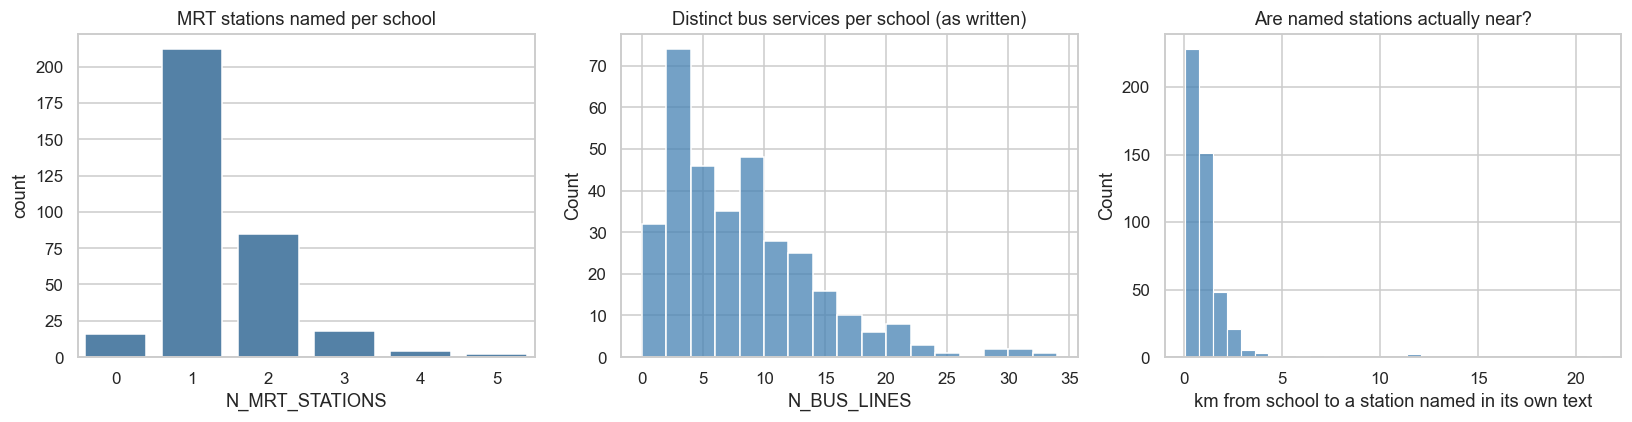

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=schools, x="N_MRT_STATIONS", color="steelblue", ax=axes[0])
axes[0].set_title("MRT stations named per school")
sns.histplot(schools["N_BUS_LINES"], bins=range(0, 36, 2), color="steelblue", ax=axes[1])
axes[1].set_title("Distinct bus services per school (as written)")
sns.histplot(pairs["dist_m"] / 1000, bins=30, color="steelblue", ax=axes[2])
axes[2].set_xlabel("km from school to a station named in its own text")
axes[2].set_title("Are named stations actually near?")
plt.tight_layout()
plt.show()

### 5e. Manual coordinate corrections (team-verified)

The team looked up the 8 flagged schools by hand (school website / address) and confirmed 7 of the 8 `COORD_SUSPECT`
rows really were wrong, plus one refinement on a `COORD_SUSPECT`-adjacent row. One pair (`gan eng seng primary school`
/ `gan eng seng school`) was checked and is **not** an error — the two campuses are genuinely close together — so it
is left as-is and stays flagged as `COORD_SHARED` only.

| School | What was wrong | Fix |
|---|---|---|
| Methodist Girls' School (Primary/Secondary) | Coordinates copied from the Paya Lebar campus (Hougang) | Moved back to 11 Blackmore Drive, Bukit Timah |
| Paya Lebar Methodist Girls' School (Primary/Secondary) | Right area, coordinates just imprecise | Refined to 298 Lorong Ah Soo / 296 Lor Ah Soo |
| St. Anthony's Primary School | Coordinates copied from St. Anthony's Canossian Primary (Bedok) | Moved back to 30 Bukit Batok St 32 |
| St. Anthony's Canossian Primary School | Right area, coordinates just imprecise | Refined to 1602 Bedok North Ave 4 |
| Outram Secondary School | `STREET` already lists the new Anchorvale (Sengkang) campus, but coordinates were still the old York Hill campus, 13.6 km away | Moved to the Anchorvale campus |
| Tao Nan School | ~7 km off with no traceable cause | Moved to 49 Marine Crescent |

In [24]:
COORD_FIXES = {
    # NAME (lowercase, matches the cleaned frame) -> (correct LATITUDE, correct LONGITUDE, why)
    "methodist girls' school (primary)": (1.3329, 103.7826,
        "own address is 11 Blackmore Drive (Bukit Timah); coordinates had been copied from the Paya Lebar campus"),
    "methodist girls' school (secondary)": (1.3329, 103.7826,
        "same address as the primary school; same copy error"),
    "paya lebar methodist girls' school (primary)": (1.3505, 103.8851,
        "refinement for 298 Lorong Ah Soo (Hougang); the flagged value was already close"),
    "paya lebar methodist girls' school (secondary)": (1.3508, 103.8855,
        "refinement for 296 Lor Ah Soo (Hougang); the flagged value was already close"),
    "st. anthony's canossian primary school": (1.3343, 103.9411,
        "refinement for 1602 Bedok North Ave 4; the flagged value was already close"),
    "st. anthony's primary school": (1.3645, 103.7492,
        "own address is 30 Bukit Batok St 32; coordinates had been copied from St. Anthony's Canossian Primary (Bedok)"),
    "outram secondary school": (1.3980, 103.8910,
        "STREET already lists the current Anchorvale (Sengkang) campus; coordinates were the old York Hill campus, 13.6 km away"),
    "tao nan school": (1.3050, 103.9113,
        "own address is 49 Marine Crescent; coordinates were ~7 km off with no traceable cause"),
}
# Not fixed: "gan eng seng primary school" / "gan eng seng school" share a coordinate, but both addresses
# (Redhill Close / Henderson Road) are genuinely close together -- team-confirmed not an error, left as-is.

for name, (lat, lon, why) in COORD_FIXES.items():
    mask = schools["NAME"] == name
    assert mask.sum() == 1, f"expected exactly one row for {name!r}"
    before = schools.loc[mask, ["LATITUDE", "LONGITUDE"]].iloc[0]
    schools.loc[mask, "LATITUDE"] = lat
    schools.loc[mask, "LONGITUDE"] = lon
    print(f"{name}: ({before.LATITUDE:.4f}, {before.LONGITUDE:.4f}) -> ({lat}, {lon})  -- {why}")

# the flags were computed before the fix, so re-derive them now that the coordinates have changed
schools["COORD_SHARED"] = schools.duplicated(["LATITUDE", "LONGITUDE"], keep=False)
schools.loc[schools["NAME"].isin(COORD_FIXES), "COORD_SUSPECT"] = False

print("\nremaining COORD_SUSPECT:", int(schools["COORD_SUSPECT"].sum()))
print("remaining COORD_SHARED:", int(schools["COORD_SHARED"].sum()), "rows ->",
      schools.loc[schools["COORD_SHARED"], "NAME"].tolist())

methodist girls' school (primary): (1.3495, 103.8850) -> (1.3329, 103.7826)  -- own address is 11 Blackmore Drive (Bukit Timah); coordinates had been copied from the Paya Lebar campus
methodist girls' school (secondary): (1.3510, 103.8851) -> (1.3329, 103.7826)  -- same address as the primary school; same copy error
paya lebar methodist girls' school (primary): (1.3495, 103.8850) -> (1.3505, 103.8851)  -- refinement for 298 Lorong Ah Soo (Hougang); the flagged value was already close
paya lebar methodist girls' school (secondary): (1.3510, 103.8851) -> (1.3508, 103.8855)  -- refinement for 296 Lor Ah Soo (Hougang); the flagged value was already close
st. anthony's canossian primary school: (1.3347, 103.9412) -> (1.3343, 103.9411)  -- refinement for 1602 Bedok North Ave 4; the flagged value was already close
st. anthony's primary school: (1.3347, 103.9412) -> (1.3645, 103.7492)  -- own address is 30 Bukit Batok St 32; coordinates had been copied from St. Anthony's Canossian Primary (Bed

### 5d. Judgment calls and what stays imperfect

- **Named ≠ nearest.** These lists are what MOE chose to write. A school can name a station 1.5 km away and omit a nearer
  one. The count is a rough signal, not a distance; distances should come from the coordinates.
- **Planned stations.** Some named stations are `planned` in the MRT table; `N_MRT_STATIONS` counts all named, `N_MRT_STATIONS_OPEN` only open ones.
- **MRT/LRT hubs.** The MRT table merges hubs (`bukit panjang mrt/lrt station`), so `bukit panjang lrt` maps to the hub, not to the LRT list.
- **LRT list is hand-written** (not from a source file) and only used to recognise names; it is not joined to any coordinates.
- **Bus counts are not comparable across schools.** Lists range from one service to 33 depending on how much the school wrote;
  a rows with `000` padding are truncated at source. Use `N_BUS_LINES` as a weak feature at most. A real measure needs
  bus-stop data (LTA) which this project does not have.
- **Bus numbers inside MRT text** (`transfer bus no.63`) are removed from the MRT parse and not added to the bus list.
- **Coordinate errors are flagged, not repaired** (`COORD_SUSPECT`, `COORD_SHARED`, see above).
- **Two-campus text** (`york hill campus ... anchorvale campus`) is merged into one list for that school.

## 6. School mix and geography


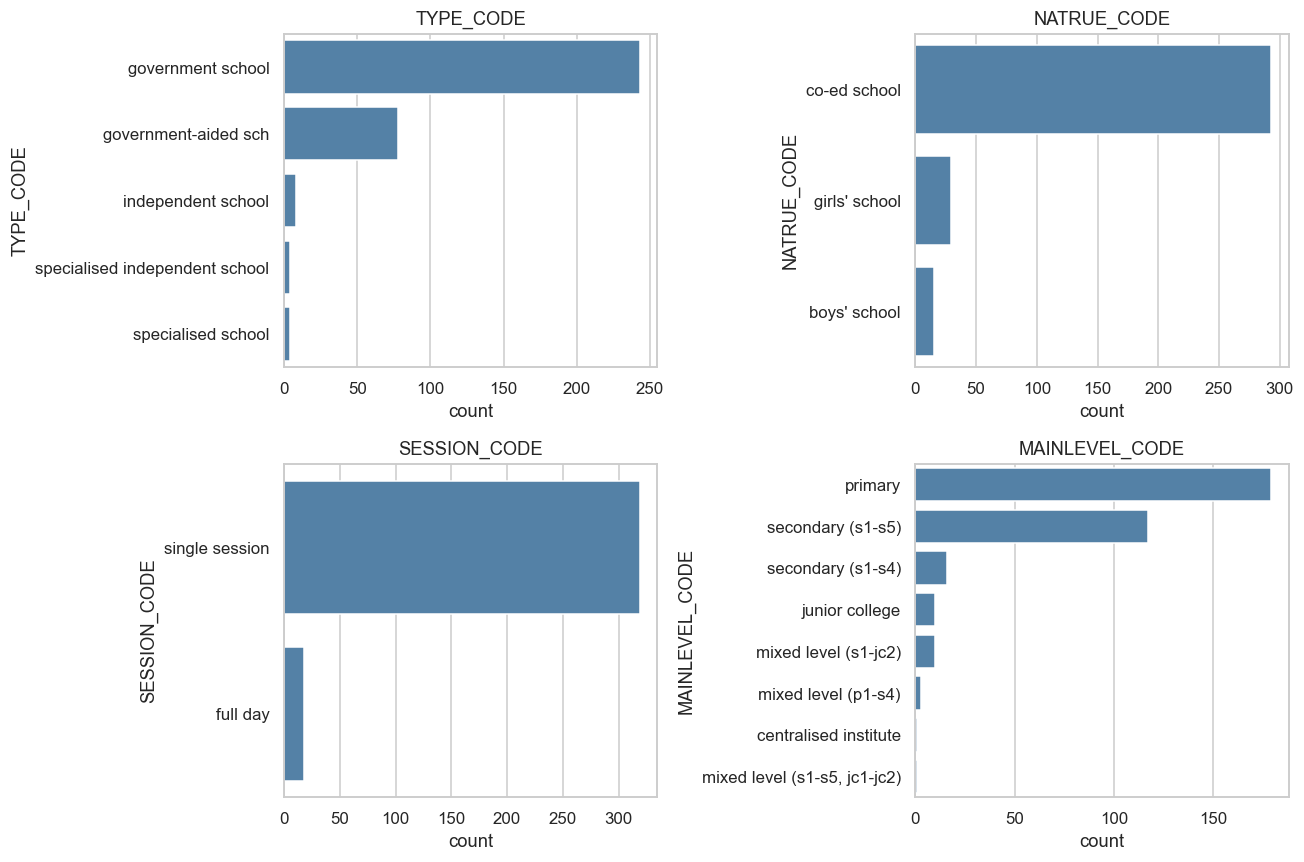

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["TYPE_CODE", "NATRUE_CODE", "SESSION_CODE", "MAINLEVEL_CODE"]):
    order = schools[col].value_counts().index
    sns.countplot(data=schools, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()


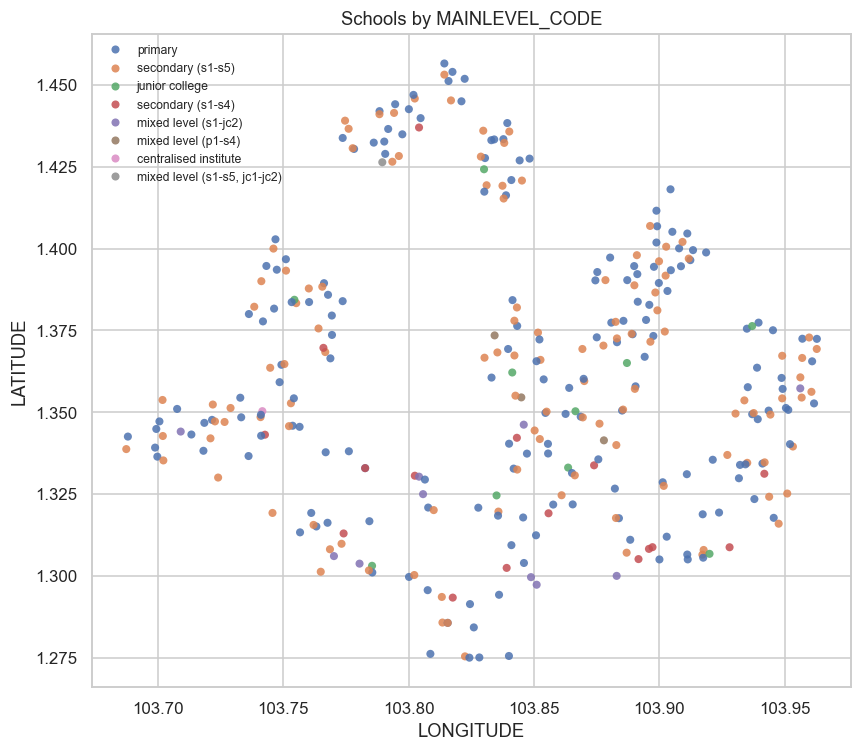

In [26]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=schools, x="LONGITUDE", y="LATITUDE", hue="MAINLEVEL_CODE",
    s=28, linewidth=0, alpha=0.85, ax=ax,
)
ax.set_title("Schools by MAINLEVEL_CODE")
ax.legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


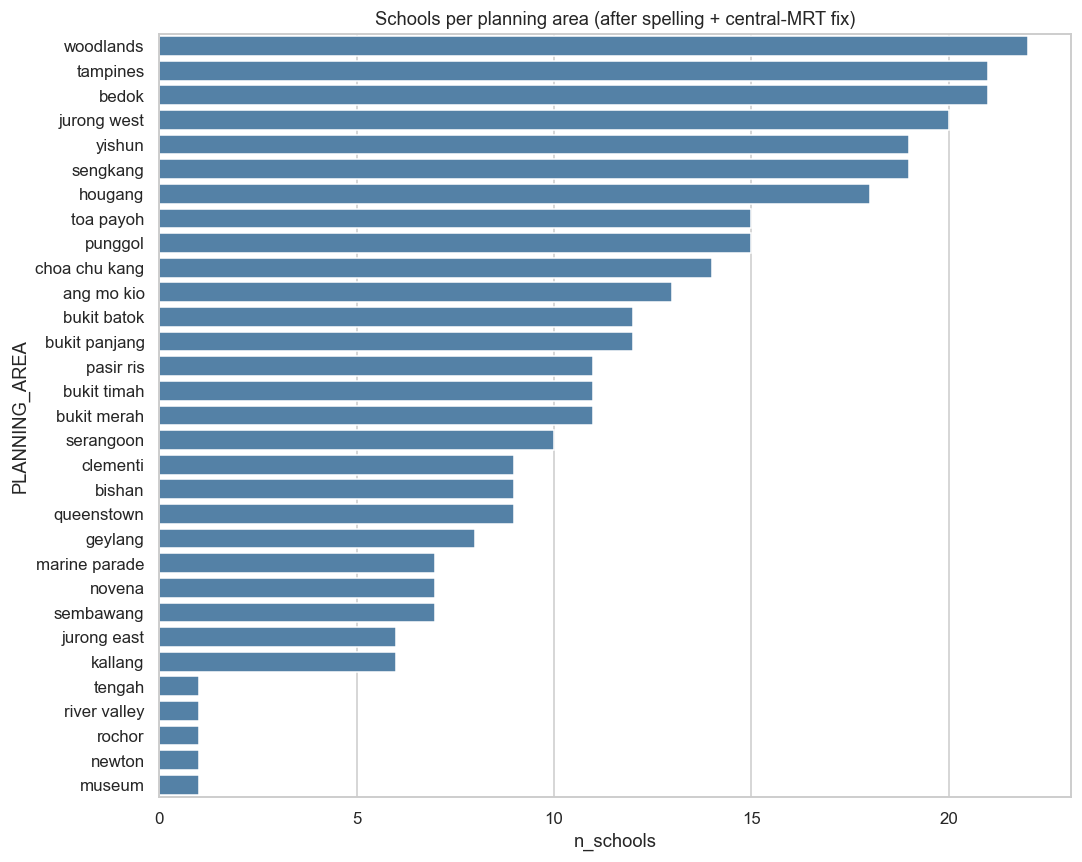

,PLANNING_AREA,n_schools
29,woodlands,22
26,tampines,21
1,bedok,21
12,jurong west,20
30,yishun,19
24,sengkang,19
10,hougang,18
28,toa payoh,15
19,punggol,15
7,choa chu kang,14


In [27]:
area = (
    schools.groupby("PLANNING_AREA").size()
    .rename("n_schools").reset_index()
    .sort_values("n_schools", ascending=False)
)
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=area, y="PLANNING_AREA", x="n_schools", ax=ax, color="steelblue")
ax.set_title("Schools per planning area (after spelling + central-MRT fix)")
plt.tight_layout()
plt.show()
area.head(10)


## 7. Area-level school features


In [28]:
school_features = schools.groupby("PLANNING_AREA").agg(
    n_schools_total=("NAME", "count"),
    n_schools_primary=("MAINLEVEL_CODE", lambda s: s.str.contains("primary", na=False).sum()),
    n_schools_secondary=("MAINLEVEL_CODE", lambda s: s.str.contains("secondary", na=False).sum()),
    n_schools_government=("TYPE_CODE", lambda s: s.str.contains("government", na=False).sum()),
).reset_index()
school_features.sort_values("n_schools_total", ascending=False).head(10)


,PLANNING_AREA,n_schools_total,n_schools_primary,n_schools_secondary,n_schools_government
29,woodlands,22,12,9,20
26,tampines,21,11,9,21
1,bedok,21,11,9,21
12,jurong west,20,10,9,20
30,yishun,19,10,8,19
24,sengkang,19,12,7,19
10,hougang,18,9,8,18
28,toa payoh,15,7,6,14
19,punggol,15,11,4,15
7,choa chu kang,14,8,5,14


## 8. Summary

- **Grain:** 337 schools, unique `NAME`, no missing cells on the raw file.
- **Join key:** `PLANNING_AREA`, after `seng kang` → `sengkang` and the 4 `central` schools
  remapped via nearest MRT. `REGION` is the URA 5-region, so it now matches HDB/MRT with no
  alias map.
- **`STREET_NAME`:** house number stripped so the column matches HDB `STREET`.
- **`NATRUE_CODE`:** source typo; values are co-ed / girls / boys.
- **`MRT_STATIONS`:** parsed into `MRT_STATIONS_CLEAN` (`;`-separated names from the MRT table),
  `LRT_STATIONS_CLEAN`, `N_MRT_STATIONS`, `N_MRT_STATIONS_OPEN`, `N_LRT_STATIONS` and a `MRT_PARSE_FLAG`. Names were
  checked against the school coordinates and the station codes quoted in the text (5c).
- **`BUS_LINES`:** parsed into `BUS_LINES_CLEAN` (`;`-separated services) and `N_BUS_LINES`; address numbers, stop ids,
  times and `000` padding were removed before extracting services. Counts are not comparable across schools (5d).
- **Coordinates:** the station-distance check found 8 schools with wrong coordinates (copied from a same-named school, or an
  outdated campus address). The team looked all 8 up by hand and fixed them in 5e; one further flagged pair
  (Gan Eng Seng Primary/Secondary) was checked and confirmed **not** an error.
- The raw columns are kept next to the parsed ones. Neither is used as a feature in `03_feature_rmse.ipynb`.
- **Zero-school HDB areas** after the fix: `outram` stays empty; `rochor` picks up School of the Arts.
- **Next:** `03_feature_rmse.ipynb` (1 km primary counts and RMSE).


In [29]:
schools.to_csv(CLEANED / "sg_schools_cleaned.csv", index=False)
school_features.to_csv(OUT / "school_features_by_area.csv", index=False)
print("wrote", CLEANED / "sg_schools_cleaned.csv", schools.shape)
print("wrote", OUT / "school_features_by_area.csv", school_features.shape)


wrote ../cleaned/sg_schools_cleaned.csv (337, 27)
wrote ../outputs/school_features_by_area.csv (31, 5)
